# Online Retail II: limpieza con anomalías desconocidas y análisis de negocio

**Datos reales:** 1.067.371 líneas de factura de un e-commerce mayorista de regalos con sede en el Reino Unido, de diciembre de 2009 a diciembre de 2011. Fuente: *Online Retail II*, UCI Machine Learning Repository (Chen, 2012), licencia CC BY 4.0.

A diferencia de un dataset simulado, acá **no se sabe de antemano qué errores hay**. El notebook sigue el orden de un trabajo real:

1. **Descubrir** las anomalías explorando los datos, sin suponerlas.
2. **Limpiar** con un pipeline reproducible (`src/limpiar_retail.py`) que clasifica cada fila en lugar de borrarla.
3. **Analizar los faltantes con rigor:** ¿falta el cliente al azar (MCAR) o según otras variables (MAR)?
4. **Detectar precios atípicos** sin confundir errores con la estructura de precios del negocio.
5. **Responder preguntas de negocio** sobre ventas netas, estacionalidad, devoluciones y concentración de clientes.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "../src")
from limpiar_retail import Log, clasificar, leer_excel, limpiar, normalizar

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 40)

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#b4b3ad"
TEXTO, TEXTO_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRILLA, "axes.labelcolor": TEXTO_2, "axes.titlecolor": TEXTO,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRILLA, "grid.linewidth": 0.8, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "font.size": 10,
})

def miles(x, decimales=0):
    # Formato argentino: 1.234.567,8
    return f"{x:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

def eje_meses(ax, cada=3):
    # Eje de fechas con meses en español, uno cada `cada` meses
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1, 13, cada)))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f"{MESES[mdates.num2date(x).month - 1]} {mdates.num2date(x).year % 100:02d}"))

def libras(x, _=None):
    return f"£ {miles(x / 1e3)} mil" if abs(x) < 1e6 else f"£ {miles(x / 1e6, 2)} M"

## 1. Carga y primera mirada

In [2]:
crudo = leer_excel(Path("../data/raw/online_retail_II.xlsx"))
print(f"{miles(len(crudo))} filas · hojas: {crudo['hoja'].value_counts().to_dict()}")
crudo.head()

1.067.371 filas · hojas: {'Year 2010-2011': 541910, 'Year 2009-2010': 525461}

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,hoja
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


In [3]:
resumen = pd.DataFrame({"faltantes": crudo.isna().sum(), "% faltantes": (crudo.isna().mean() * 100).round(2),
                        "valores únicos": crudo.nunique()})
resumen

,faltantes,% faltantes,valores únicos
Invoice,0,0.00,53628
StockCode,0,0.00,5305
Description,4382,0.41,5698
Quantity,0,0.00,1057
InvoiceDate,0,0.00,47635
Price,0,0.00,2807
Customer ID,243007,22.77,5942
Country,0,0.00,43
hoja,0,0.00,2


In [4]:
crudo[["Quantity", "Price"]].describe(percentiles=[0.01, 0.5, 0.99]).round(2)

,Quantity,Price
count,1067371.00,1067371.00
mean,9.94,4.65
std,172.71,123.55
min,-80995.00,-53594.36
1%,-3.00,0.21
50%,3.00,2.10
99%,100.00,18.00
max,80995.00,38970.00


Ya en la descripción aparecen señales: cantidades de **−80.995 y +80.995**, precios **negativos** de hasta −53.594 y un 23% de líneas **sin cliente**. Nada de eso se corrige todavía: primero hay que entender qué significa cada cosa.

## 2. Descubrimiento de anomalías

### 2.1 Las dos hojas se superponen

In [5]:
rangos = crudo.groupby("hoja")["InvoiceDate"].agg(["min", "max"])
print(rangos, "\n")
h1, h2 = rangos.index
ventana_1 = crudo[(crudo["hoja"] == h1) & (crudo["InvoiceDate"] >= rangos.loc[h2, "min"])].drop(columns="hoja")
ventana_2 = crudo[(crudo["hoja"] == h2) & (crudo["InvoiceDate"] <= rangos.loc[h1, "max"])].drop(columns="hoja")
ordenar = lambda d: d.sort_values(list(d.columns)).reset_index(drop=True)
print(f"Filas en la ventana compartida: {miles(len(ventana_1))} en '{h1}' y {miles(len(ventana_2))} en '{h2}'")
print("¿Son idénticas?", ordenar(ventana_1).equals(ordenar(ventana_2)))

                               min                 max
hoja                                                  
Year 2009-2010 2009-12-01 07:45:00 2010-12-09 20:01:00
Year 2010-2011 2010-12-01 08:26:00 2011-12-09 12:50:00 

Filas en la ventana compartida: 22.523 en 'Year 2009-2010' y 22.523 en 'Year 2010-2011'
¿Son idénticas? True

Las dos hojas repiten **exactamente** las transacciones del 1 al 9 de diciembre de 2010. Si se concatenan sin revisar, ese período se cuenta dos veces. Es el típico error que no aparece en un dataset simulado.

### 2.2 Tipos de factura y cantidades negativas

In [6]:
df = crudo[~crudo.index.isin(ventana_1.index)].copy()   # sin la superposición
prefijo = df["Invoice"].str.extract(r"^([A-Za-z]?)")[0].replace("", "(número)")
pd.crosstab(prefijo, np.sign(df["Quantity"]).map({-1: "cantidad < 0", 1: "cantidad > 0"}), margins=True, margins_name="total")

Quantity,cantidad < 0,cantidad > 0,total
0,,,
(número),3393,1022284,1025677
A,0,6,6
C,19164,1,19165
total,22557,1022291,1044848


In [7]:
# Cantidades negativas en facturas normales (sin "C"): ¿qué son?
neg = df[(prefijo == "(número)") & (df["Quantity"] < 0)]
print(f"{miles(len(neg))} filas · precio 0: {neg['Price'].eq(0).mean():.0%} · con cliente: {neg['Customer ID'].notna().mean():.0%}")
neg["Description"].fillna("<vacía>").str.lower().value_counts().head(12)

3.393 filas · precio 0: 100% · con cliente: 0%

Description
<vacía>                   2633
check                      124
damaged                     96
damages                     88
?                           81
missing                     30
sold as set on dotcom       20
dotcom                      11
smashed                      9
thrown away                  9
unsaleable, destroyed.       9
given away                   8
Name: count, dtype: int64

Esas líneas no son ventas ni devoluciones. Tienen precio 0, ningún cliente y descripciones como *damaged*, *missing*, *thrown away* o *check*: son **ajustes de inventario** (mercadería rota, perdida o recontada) cargados en el mismo sistema que las ventas. Las facturas **"C"** son devoluciones o cancelaciones, y las **"A"** son ajustes por deudas incobrables.

### 2.3 Códigos que no son productos

In [8]:
codigo = df["StockCode"].str.strip().str.upper()
es_producto = codigo.str.fullmatch(r"\d{5}[A-Z]{0,2}")
especiales = (df[~es_producto].assign(codigo=codigo, importe=df["Quantity"] * df["Price"])
              .groupby("codigo").agg(filas=("Invoice", "size"), descripcion=("Description", lambda s: s.dropna().mode().iat[0] if s.notna().any() else ""),
                                     importe=("importe", "sum"))
              .sort_values("filas", ascending=False))
print(f"{len(especiales)} códigos fuera del formato de producto ({(~es_producto).mean():.2%} de las filas)")
especiales.head(16).round(0)

61 códigos fuera del formato de producto (0.57% de las filas)

,filas,descripcion,importe
codigo,,,
POST,2086,POSTAGE,110430.0
DOT,1425,DOTCOM POSTAGE,309844.0
M,1403,Manual,-82936.0
C2,277,CARRIAGE,13136.0
D,173,Discount,-12880.0
S,102,SAMPLES,-6001.0
BANK CHARGES,100,Bank Charges,-35482.0
ADJUST,67,Adjustment by john on 26/01/2010 16,6835.0
AMAZONFEE,36,AMAZON FEE,-221520.0


Hay cargos de envío (**POST**, **DOT**, **C2**), comisiones de Amazon, cargos bancarios, descuentos, ajustes manuales, vales de regalo y hasta productos de prueba (**TEST001**). Los códigos **DCGS…** sí son productos (de la tienda online). Además:

In [9]:
minus = df["StockCode"].str.strip()[df["StockCode"].str.strip().str.fullmatch(r"\d{5}[a-z]+")].unique()
gemelos = [c for c in minus if c.upper() in set(df["StockCode"].str.strip())]
print(f"Códigos en minúscula: {len(minus)}, de los cuales {len(gemelos)} existen también en mayúscula (ej. {gemelos[0]} / {gemelos[0].upper()})")
print("Código con espacio al final:", [c for c in df["StockCode"].unique() if c != c.strip()])
varias = df[es_producto].groupby(codigo)["Description"].nunique()
print(f"Productos con más de una descripción: {miles((varias > 1).sum())} de {miles(len(varias))}")
print("Ejemplo:", df[codigo == "10120"]["Description"].value_counts().to_dict())

Códigos en minúscula: 173, de los cuales 172 existen también en mayúscula (ej. 72349b / 72349B)
Código con espacio al final: ['47503J ']
Productos con más de una descripción: 1.202 de 5.070
Ejemplo: {'DOGGY RUBBER': 75, 'Zebra invcing error': 1}

**Resumen del descubrimiento:** superposición de hojas, ajustes de inventario mezclados con ventas, devoluciones, ajustes contables, códigos de servicio, variantes de mayúsculas en los códigos y descripciones "contaminadas" por textos de control. Con eso se diseñaron las reglas del pipeline.

## 3. Limpieza con el pipeline

`src/limpiar_retail.py` **clasifica cada fila** en un tipo de movimiento. Nada se borra en silencio: cada tipo responde a una pregunta distinta (las ventas sirven para analizar demanda, los ajustes de inventario para medir mermas, las devoluciones para medir calidad).

In [10]:
ventas, devoluciones, otros, log = limpiar(crudo)
log

,paso,filas,detalle
0,Filas leídas,1067371,2 hoja(s)
1,Quitar superposición de hojas,22523,'Year 2009-2010' repetía 01/12/2010–09/12/2010 de 'Year 2010-2011' (idéntico)
2,Normalizar códigos,3346,códigos con minúsculas o espacios unificados (ej. '72349b' → '72349B')
3,Clasificar: venta,1015088,venta de productos (cantidad y precio positivos)
4,Clasificar: devolucion,17974,factura 'C' de un producto: devolución o cancelación
5,Clasificar: envio,3788,"cargos de envío (POST, DOT, C2): ingreso, pero no venta de producto"
6,Clasificar: ajuste_contable,1906,"deudas incobrables, comisiones, cargos bancarios, descuentos y ajustes manuales"
7,Clasificar: ajuste_inventario,5936,"precio 0 y sin cliente: mercadería dañada, perdida o encontrada"
8,Clasificar: sin_cargo,61,precio 0 con cliente: entregas sin cargo
9,Clasificar: vale_regalo,78,venta de vales de regalo (no es un producto físico)


Filas de entrada sin superposición: 1.044.848 · filas clasificadas: 1.044.848

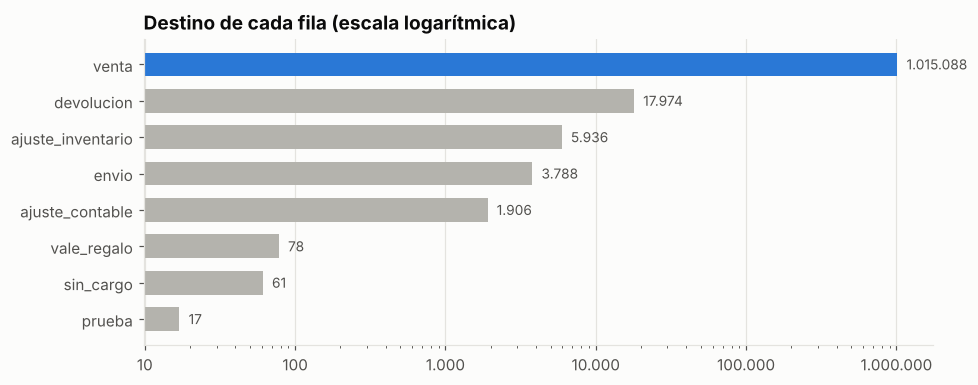

,filas,importe,% filas
tipo,,,
venta,1015088,"£ 19,70 M",97.15
devolucion,17974,£ -720 mil,1.72
ajuste_inventario,5936,£ 0 mil,0.57
envio,3788,£ 433 mil,0.36
ajuste_contable,1906,£ -507 mil,0.18
vale_regalo,78,£ 2 mil,0.01
sin_cargo,61,£ 0 mil,0.01
prueba,17,£ 0 mil,0.00


In [11]:
# Conciliación: destino de cada fila e importe de cada tipo
todo = pd.concat([ventas.assign(tipo="venta"), devoluciones.assign(tipo="devolucion"), otros])
conciliacion = todo.groupby("tipo").agg(filas=("factura", "size"), importe=("importe", "sum")).sort_values("filas", ascending=False)
conciliacion["% filas"] = (conciliacion["filas"] / conciliacion["filas"].sum() * 100).round(2)
print(f"Filas de entrada sin superposición: {miles(len(df))} · filas clasificadas: {miles(conciliacion['filas'].sum())}")

fig, ax = plt.subplots(figsize=(9, 3.6))
orden = conciliacion["filas"].sort_values()
ax.barh(orden.index, orden.values, color=[AZUL if t == "venta" else GRIS for t in orden.index], height=0.65)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: miles(x)))
for y, v in enumerate(orden.values):
    ax.text(v * 1.15, y, miles(v), va="center", color=TEXTO_2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_title("Destino de cada fila (escala logarítmica)")
plt.tight_layout(); plt.savefig("../figures/01_destino_filas.png", dpi=150, bbox_inches="tight")
conciliacion.assign(importe=conciliacion["importe"].map(lambda x: libras(x)))

## 4. Clientes faltantes: ¿MCAR, MAR o MNAR?

El 23% de las líneas no tiene `Customer ID`. Antes de decidir qué hacer hay que saber **por qué falta**:

- **MCAR** (*missing completely at random*): falta por azar. Descartar esas filas no sesga nada.
- **MAR** (*missing at random*): la falta depende de variables **observadas** (país, precio, tamaño del pedido). Descartarlas sesga los resultados, pero el sesgo se puede describir y controlar.
- **MNAR**: depende del propio valor faltante. No se puede probar con los datos; solo se puede argumentar.

**Primera pista: ¿falta por línea o por factura?**

In [12]:
f = (ventas.groupby("factura")
     .agg(sin_cliente=("tiene_cliente", lambda s: (~s).mean()), lineas=("codigo", "size"), importe=("importe", "sum"),
          precio_mediano=("precio", "median"), pais=("pais", "first"), fecha=("fecha", "first")))
print("Facturas según la proporción de líneas sin cliente:")
print(pd.cut(f["sin_cliente"], [-0.01, 0, 0.99, 1], labels=["0% (todas con cliente)", "mixtas", "100% (todas sin cliente)"]).value_counts())
f["falta"] = f["sin_cliente"] == 1

Facturas según la proporción de líneas sin cliente:
sin_cliente
0% (todas con cliente)      36594
100% (todas sin cliente)     2922
mixtas                          0
Name: count, dtype: int64

**Nunca** falta en algunas líneas de una factura y en otras no. El faltante se genera a nivel de pedido, no por un error de tipeo al azar. Eso ya hace poco creíble la hipótesis MCAR. A continuación se compara el perfil de los pedidos con y sin cliente.

In [13]:
comparacion = f.groupby("falta")[["lineas", "importe", "precio_mediano"]].median().T
comparacion.columns = ["con cliente", "sin cliente"]
comparacion["razón sin/con"] = (comparacion["sin cliente"] / comparacion["con cliente"]).round(2)
comparacion["p-valor (Mann-Whitney)"] = [stats.mannwhitneyu(f.loc[f.falta, c], f.loc[~f.falta, c]).pvalue for c in comparacion.index]
comparacion["p-valor (Mann-Whitney)"] = comparacion["p-valor (Mann-Whitney)"].map(lambda p: f"{p:.1e}")
comparacion.round(2)

,con cliente,sin cliente,razón sin/con,p-valor (Mann-Whitney)
lineas,15.00,20.00,1.33,2.5e-22
importe,303.10,184.48,0.61,6.0e-30
precio_mediano,1.96,3.36,1.71,1.3e-293


In [14]:
tabla_pais = pd.crosstab(f["pais"] == "United Kingdom", f["falta"])
chi2, p_pais, *_ = stats.chi2_contingency(tabla_pais)
n = tabla_pais.values.sum()
v_cramer = np.sqrt(chi2 / n)
print(f"País (Reino Unido vs. resto): chi² = {chi2:.0f}, p = {p_pais:.1e}, V de Cramér = {v_cramer:.2f}")
print(f"% de pedidos sin cliente — Reino Unido: {f[f.pais == 'United Kingdom'].falta.mean():.1%} · resto: {f[f.pais != 'United Kingdom'].falta.mean():.1%}")

País (Reino Unido vs. resto): chi² = 103, p = 2.9e-24, V de Cramér = 0.05
% de pedidos sin cliente — Reino Unido: 7.8% · resto: 3.0%

Con casi 40.000 pedidos, **cualquier diferencia da p < 0,05**: el p-valor dice que la diferencia existe, no que importe. Por eso se miran los **tamaños de efecto**. Los pedidos sin cliente pagan un precio unitario mediano **1,7 veces más alto**, tienen más líneas y un importe total menor. La diferencia por país es real pero chica (V de Cramér de 0,05). Es el perfil de un **comprador minorista sin cuenta**, que paga precio de lista, frente al mayorista registrado.

**Prueba formal:** si los datos fueran MCAR, ninguna variable observada debería poder predecir el faltante. Se entrena una regresión logística con validación cruzada:

In [15]:
X = pd.DataFrame({
    "log_importe": np.log1p(f["importe"]), "log_lineas": np.log(f["lineas"]),
    "log_precio_mediano": np.log(f["precio_mediano"]), "reino_unido": (f["pais"] == "United Kingdom").astype(int),
    "mes": f["fecha"].dt.month, "anio_2011": (f["fecha"].dt.year == 2011).astype(int),
})
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
auc = cross_val_score(modelo, X, f["falta"], cv=5, scoring="roc_auc")
print(f"AUC con validación cruzada (5 particiones): {auc.mean():.3f} ± {auc.std():.3f}")
print("Bajo MCAR, el AUC esperado es 0,5 (el modelo no podría distinguir mejor que tirar una moneda).")

AUC con validación cruzada (5 particiones): 0.875 ± 0.024
Bajo MCAR, el AUC esperado es 0,5 (el modelo no podría distinguir mejor que tirar una moneda).

Las ventas sin cliente representan el 13.1% de la facturación de productos.

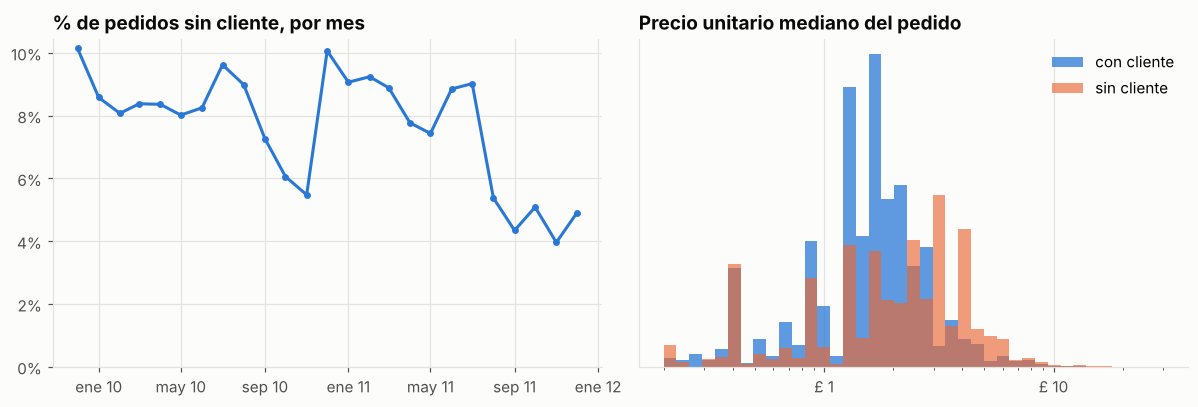

In [16]:
mensual = f.groupby(f["fecha"].dt.to_period("M"))["falta"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(mensual.index.to_timestamp(), mensual.values, color=AZUL, linewidth=2, marker="o", markersize=3.5)
axes[0].set_ylim(0); axes[0].set_title("% de pedidos sin cliente, por mes")
eje_meses(axes[0], cada=4)
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
bins = np.logspace(np.log10(0.2), np.log10(30), 40)
axes[1].hist(f.loc[~f.falta, "precio_mediano"], bins=bins, color=AZUL, alpha=0.75, label="con cliente", density=True)
axes[1].hist(f.loc[f.falta, "precio_mediano"], bins=bins, color=NARANJA, alpha=0.65, label="sin cliente", density=True)
axes[1].set_xscale("log"); axes[1].set_title("Precio unitario mediano del pedido")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£ {miles(x, 1 if x < 1 else 0)}"))
axes[1].legend(frameon=False); axes[1].set_yticks([]); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("../figures/02_clientes_faltantes.png", dpi=150, bbox_inches="tight")

importe_sin = ventas.loc[~ventas.tiene_cliente, "importe"].sum() / ventas["importe"].sum()
print(f"Las ventas sin cliente representan el {importe_sin:.1%} de la facturación de productos.")

**Conclusión sobre los faltantes:**

- **No es MCAR.** El faltante es por pedido completo y es predecible a partir de variables observadas (ver el AUC).
- **Es compatible con MAR:** depende del canal o tipo de comprador (precio de lista, Reino Unido, pedidos de menor importe). No se puede descartar MNAR (por definición no es comprobable), pero la explicación del canal es coherente con todos los indicios.
- **Decisión:** no tiene sentido imputar un ID de cliente, porque inventaría personas. Las ventas sin cliente **se conservan** en todo análisis de facturación y demanda; eliminarlas subestimaría la facturación y sesgaría la mezcla de productos hacia el canal mayorista. Se excluyen **solo** del análisis por cliente, y se aclara que ese análisis describe a los clientes registrados, mayormente mayoristas.

## 5. Precios atípicos: errores vs. estructura del negocio

El enfoque de manual es un **z-score robusto** por producto, $z = 0{,}6745 \cdot (\log p - \text{mediana}) / \text{MAD}$, marcando $|z| > 3{,}5$ (Iglewicz y Hoaglin, 1993). Veamos qué pasa con estos datos:

In [17]:
log_p = np.log(ventas["precio"])
mediana = log_p.groupby(ventas["codigo"]).transform("median")
mad = (log_p - mediana).abs().groupby(ventas["codigo"]).transform("median")
z = 0.6745 * (log_p - mediana) / mad.replace(0, np.nan)
razon = ventas["precio"] / np.exp(mediana)
print(f"Ventas en productos con MAD = 0 (precio casi constante): {(mad == 0).mean():.0%} → el z-score no se puede calcular")
print(f"Ventas marcadas por el z-score robusto: {miles((z.abs() > 3.5).sum())}")
print(f"Razón precio/habitual de esas ventas (mediana): {razon[z.abs() > 3.5].median():.2f}")

Ventas en productos con MAD = 0 (precio casi constante): 84% → el z-score no se puede calcular
Ventas marcadas por el z-score robusto: 26.643
Razón precio/habitual de esas ventas (mediana): 1.82

Razones más frecuentes: {'1.0×': '714.201', '2.0×': '100.131', '0.9×': '35.633', '0.8×': '22.724'}

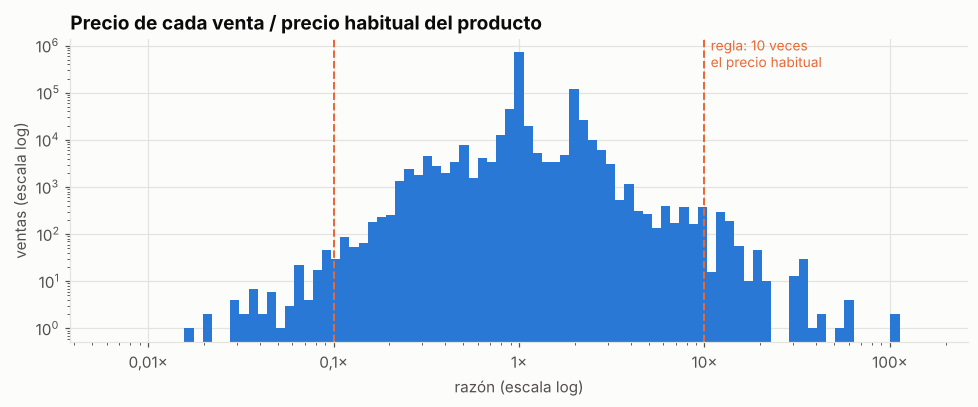

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.logspace(-2.2, 2.2, 90)
ax.hist(razon, bins=bins, color=AZUL)
ax.set_xscale("log"); ax.set_yscale("log")
for limite in (0.1, 10):
    ax.axvline(limite, color=NARANJA, linestyle="--", linewidth=1.3)
ax.text(10.8, ax.get_ylim()[1] * 0.25, "regla: 10 veces\nel precio habitual", color=NARANJA, fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{miles(x, 2 if x < 0.1 else (1 if x < 1 else 0))}×"))
ax.set_title("Precio de cada venta / precio habitual del producto")
ax.set_xlabel("razón (escala log)"); ax.set_ylabel("ventas (escala log)")
plt.tight_layout(); plt.savefig("../figures/03_razon_precios.png", dpi=150, bbox_inches="tight")
picos = razon.round(1).value_counts().head(4)
print("Razones más frecuentes:", {f"{k}×": miles(v) for k, v in picos.items()})

La distribución tiene **dos picos legítimos**: el precio habitual (1×) y el precio minorista, cerca de **2× el mayorista**. El z-score robusto marca como "atípicas" miles de ventas minoristas normales. Además, en la mayoría de los productos el precio es casi constante (MAD = 0), y ahí el método directamente no funciona.

Por eso el pipeline usa una regla **acorde a la estructura del negocio**: marca solo los precios que están **10 veces** por encima o por debajo del habitual (al menos 5 ventas del producto para estimarlo). Esto separa errores de carga de la estructura de precios:

In [19]:
atipicos = ventas[ventas["precio_atipico"]]
print(f"Ventas marcadas: {miles(len(atipicos))} ({len(atipicos) / len(ventas):.3%}) · "
      f"importe: {libras(atipicos['importe'].sum())} ({atipicos['importe'].sum() / ventas['importe'].sum():.2%} de la facturación)")
print(f"Sin cliente: {(~atipicos['tiene_cliente']).mean():.0%} (vs. {(~ventas['tiene_cliente']).mean():.0%} en el total)")
(atipicos.assign(razon=(atipicos["precio"] / atipicos["precio_referencia"]).round(1))
 .sort_values("razon", ascending=False)[["factura", "codigo", "descripcion", "cantidad", "precio", "precio_referencia", "razon", "cliente_id"]]
 .head(8))

Ventas marcadas: 881 (0.087%) · importe: £ 76 mil (0.39% de la facturación)
Sin cliente: 86% (vs. 22% en el total)

,factura,codigo,descripcion,cantidad,precio,precio_referencia,razon,cliente_id
185734,507637,84016,FLAG OF ST GEORGE CAR FLAG,1,1157.15,0.42,2755.1,<NA>
131612,502451,84016,FLAG OF ST GEORGE CAR FLAG,1,867.79,0.42,2066.2,<NA>
174992,506571,84016,FLAG OF ST GEORGE CAR FLAG,1,408.40,0.42,972.4,<NA>
110158,500315,84016,FLAG OF ST GEORGE CAR FLAG,1,280.75,0.42,668.5,<NA>
240131,513439,84016,FLAG OF ST GEORGE CAR FLAG,1,272.27,0.42,648.3,<NA>
131689,502469,84016,FLAG OF ST GEORGE CAR FLAG,1,93.61,0.42,222.9,<NA>
113799,500586,84016,FLAG OF ST GEORGE CAR FLAG,2,93.61,0.42,222.9,<NA>
703569,556446,22502,PICNIC BASKET WICKER SMALL,1,649.50,5.95,109.2,15098


Un banderín de auto con precio habitual de £ 0,42 cobrado a £ 1.157: son errores de carga manual. **Decisión:** las ventas marcadas se excluyen del análisis de precios y de productos, y se **conservan** en la facturación total, porque representan un porcentaje mínimo y no hay forma de saber el monto correcto. Si el negocio confirmara que son errores, el pipeline ya las tiene identificadas.

### 5.1 Líneas repetidas: análisis de sensibilidad

In [20]:
rep = ventas[ventas["linea_repetida"]]
print(f"Líneas idénticas dentro de una factura: {miles(len(rep))} ({len(rep) / len(ventas):.2%}) en {miles(rep['factura'].nunique())} facturas")
print(f"Si se eliminaran, la facturación bajaría {rep['importe'].sum() / ventas['importe'].sum():.2%}")

Líneas idénticas dentro de una factura: 11.733 (1.16%) en 4.335 facturas
Si se eliminaran, la facturación bajaría 0.29%

Sin un ID de línea no se puede saber si son un error de exportación o el mismo producto agregado dos veces al pedido, algo frecuente en una tienda online. El impacto en la facturación es menor al 1%. **Decisión:** se conservan y quedan marcadas en la columna `linea_repetida`. Ninguna conclusión de negocio cambia con una u otra opción.

## 6. Análisis de negocio

Se usa **facturación neta = ventas − devoluciones** de productos. Diciembre de 2011 tiene datos solo hasta el día 9, así que se muestra aparte.

Dic 2009–Nov 2010: £ 9,19 M · Dic 2010–Nov 2011: £ 9,35 M · variación: +1.8%
Peso de septiembre a noviembre en el año: 36% (2010) y 38% (2011)

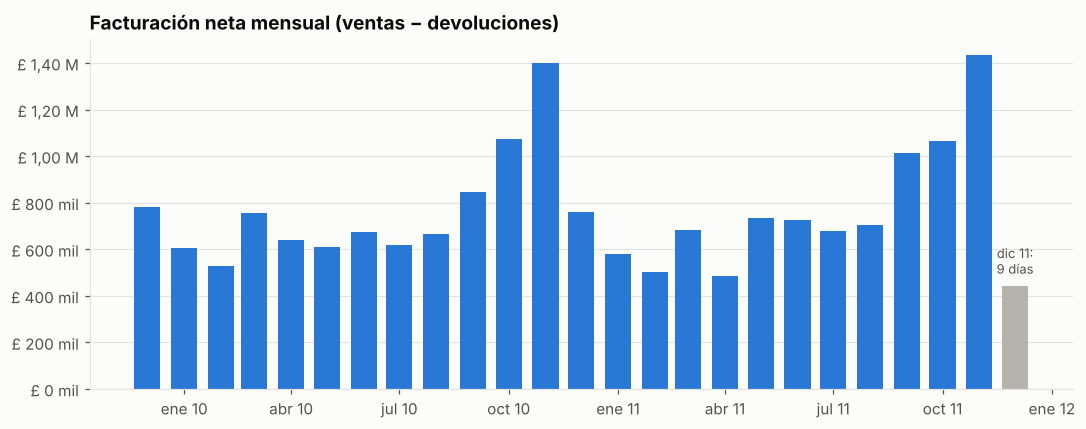

In [21]:
v_mes = ventas.groupby(ventas["fecha"].dt.to_period("M"))["importe"].sum()
d_mes = devoluciones.groupby(devoluciones["fecha"].dt.to_period("M"))["importe"].sum()
neto = (v_mes + d_mes.reindex(v_mes.index, fill_value=0))
parcial = neto.index == pd.Period("2011-12", "M")

fig, ax = plt.subplots(figsize=(10, 4))
x = neto.index.to_timestamp()
ax.bar(x, neto.values, width=22, color=[GRIS if p else AZUL for p in parcial])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(libras))
ax.set_title("Facturación neta mensual (ventas − devoluciones)")
ax.grid(axis="x", visible=False)
eje_meses(ax, cada=3)
ax.text(x[-1], neto.iloc[-1] + 40000, "dic 11:\n9 días", ha="center", va="bottom", fontsize=8.5, color=TEXTO_2)
plt.tight_layout(); plt.savefig("../figures/04_facturacion_mensual.png", dpi=150, bbox_inches="tight")

anio1 = neto[pd.Period("2009-12", "M"):pd.Period("2010-11", "M")].sum()
anio2 = neto[pd.Period("2010-12", "M"):pd.Period("2011-11", "M")].sum()
print(f"Dic 2009–Nov 2010: {libras(anio1)} · Dic 2010–Nov 2011: {libras(anio2)} · variación: {anio2 / anio1 - 1:+.1%}")
sep_nov = neto[[pd.Period(m, "M") for m in ("2010-09", "2010-10", "2010-11")]].sum() / anio1
sep_nov2 = neto[[pd.Period(m, "M") for m in ("2011-09", "2011-10", "2011-11")]].sum() / anio2
print(f"Peso de septiembre a noviembre en el año: {sep_nov:.0%} (2010) y {sep_nov2:.0%} (2011)")

In [22]:
# Devoluciones vs. anulaciones dentro de las 24 h (pedido corregido)
anul = devoluciones[devoluciones["anulacion_24h"]]
dev = devoluciones[~devoluciones["anulacion_24h"]]
brutas = ventas["importe"].sum()
print(f"Facturas 'C' de productos: {libras(-devoluciones['importe'].sum())} ({-devoluciones['importe'].sum() / brutas:.1%} de las ventas brutas)")
print(f"  · anulaciones dentro de las 24 h: {libras(-anul['importe'].sum())} ({miles(len(anul))} líneas)")
print(f"  · devoluciones propiamente dichas: {libras(-dev['importe'].sum())} = {-dev['importe'].sum() / brutas:.1%} de las ventas brutas")
print(f"Devoluciones con compra previa identificada: {dev['factura_compra'].notna().mean():.0%} · "
      f"días entre compra y devolución (mediana): {dev['dias_desde_compra'].median():.0f}")
print("Las devoluciones sin compra previa se concentran al inicio (compras anteriores a dic 2009):",
      dev.loc[dev.factura_compra.isna() & dev.cliente_id.notna(), "fecha"].dt.to_period("Q").value_counts().sort_index().head(3).to_dict())

Facturas 'C' de productos: £ 720 mil (3.7% de las ventas brutas)
  · anulaciones dentro de las 24 h: £ 351 mil (1.290 líneas)
  · devoluciones propiamente dichas: £ 369 mil = 1.9% de las ventas brutas
Devoluciones con compra previa identificada: 89% · días entre compra y devolución (mediana): 12
Las devoluciones sin compra previa se concentran al inicio (compras anteriores a dic 2009): {Period('2009Q4', 'Q-DEC'): 645, Period('2010Q1', 'Q-DEC'): 343, Period('2010Q2', 'Q-DEC'): 242}

**Una anomalía que solo aparece en datos reales.** Al ordenar productos por unidades devueltas, varios dan exactamente ~49%. Todos vienen de una misma factura:

In [23]:
lote = devoluciones[devoluciones["factura"] == "C524235"]
print(f"C524235: anula {len(lote)} líneas ({miles(-lote['cantidad'].sum())} unidades) de la factura {lote['factura_compra'].mode().iat[0]} "
      f"del cliente {lote['cliente_id'].iat[0]:.0f}, {lote['dias_desde_compra'].median():.0f} días después de la compra")
mismo_lote = ventas[ventas["factura"] == "524174"]
coincide = mismo_lote.merge(lote.assign(cantidad=-lote["cantidad"])[["codigo", "cantidad", "precio"]], on=["codigo", "cantidad", "precio"])
print(f"La factura 524174 (cliente {mismo_lote['cliente_id'].iat[0]:.0f}, emitida un día antes) repite {len(coincide)} de esas "
      f"{len(lote)} líneas con la misma cantidad y precio → es una REFACTURACIÓN a otro cliente, no una devolución.")

C524235: anula 45 líneas (87.167 unidades) de la factura 518505 del cliente 14277, 49 días después de la compra
La factura 524174 (cliente 13687, emitida un día antes) repite 44 de esas 45 líneas con la misma cantidad y precio → es una REFACTURACIÓN a otro cliente, no una devolución.

Medir la devolución en **unidades** queda dominado por unos pocos lotes grandes como este. Una métrica robusta es la **frecuencia**: qué porcentaje de las compras de un producto termina en una devolución.

In [24]:
compras = ventas.groupby("codigo")["factura"].nunique()
con_dev = dev[dev["factura_compra"].notna()].groupby("codigo")["factura_compra"].nunique()
por_prod = pd.DataFrame({"compras": compras, "compras_con_devolucion": con_dev}).fillna(0)
por_prod = por_prod[por_prod["compras"] >= 300]
por_prod["tasa_devolucion"] = por_prod["compras_con_devolucion"] / por_prod["compras"]
por_prod["descripcion"] = ventas.drop_duplicates("codigo").set_index("codigo")["descripcion"]
print(f"Productos con al menos 300 compras: {len(por_prod)} · % mediano de compras con devolución: {por_prod['tasa_devolucion'].median():.1%}")
por_prod.sort_values("tasa_devolucion", ascending=False).head(8)[["descripcion", "compras", "compras_con_devolucion", "tasa_devolucion"]].round(3)

Productos con al menos 300 compras: 950 · % mediano de compras con devolución: 0.8%

,descripcion,compras,compras_con_devolucion,tasa_devolucion
codigo,,,,
79323W,WHITE CHERRY LIGHTS,349,85.0,0.244
75049L,LARGE CIRCULAR MIRROR MOBILE,344,42.0,0.122
21527,RED RETROSPOT TRADITIONAL TEAPOT,831,95.0,0.114
37449,CERAMIC CAKE STAND + HANGING CAKES,477,50.0,0.105
22236,CAKE STAND 3 TIER MAGIC GARDEN,421,44.0,0.105
22061,LARGE CAKE STAND HANGING STRAWBERY,520,53.0,0.102
23169,CLASSIC GLASS COOKIE JAR,314,31.0,0.099
22634,CHILDS BREAKFAST SET SPACEBOY,499,46.0,0.092


Clientes registrados con compras netas positivas: 5.832
El 1% de los clientes genera el 31% de la facturación registrada; el 20%, el 77%

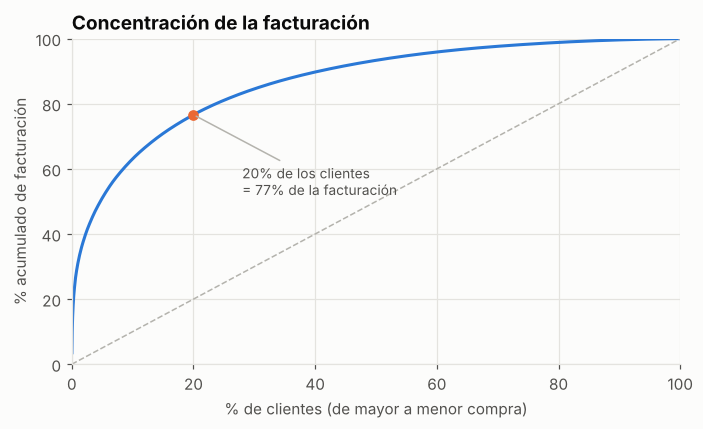

In [25]:
# Concentración de clientes (solo clientes registrados: ver sección 4)
por_cliente = (ventas[ventas.tiene_cliente].groupby("cliente_id")["importe"].sum()
               .sub(devoluciones[devoluciones.cliente_id.notna()].groupby("cliente_id")["importe"].sum().mul(-1), fill_value=0)
               .sort_values(ascending=False))
por_cliente = por_cliente[por_cliente > 0]
acum = por_cliente.cumsum() / por_cliente.sum()
top20 = acum.iloc[int(len(acum) * 0.2) - 1]
top1 = acum.iloc[int(len(acum) * 0.01) - 1]
print(f"Clientes registrados con compras netas positivas: {miles(len(por_cliente))}")
print(f"El 1% de los clientes genera el {top1:.0%} de la facturación registrada; el 20%, el {top20:.0%}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(np.arange(1, len(acum) + 1) / len(acum) * 100, acum.values * 100, color=AZUL, linewidth=2)
ax.plot([0, 100], [0, 100], color=GRIS, linestyle="--", linewidth=1)
ax.scatter([20], [top20 * 100], color=NARANJA, zorder=3)
ax.annotate(f"20% de los clientes\n= {top20:.0%} de la facturación", (20, top20 * 100), xytext=(28, 52), fontsize=9,
            color=TEXTO_2, arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set_xlabel("% de clientes (de mayor a menor compra)"); ax.set_ylabel("% acumulado de facturación")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title("Concentración de la facturación")
plt.tight_layout(); plt.savefig("../figures/05_concentracion_clientes.png", dpi=150, bbox_inches="tight")

In [26]:
# Clientes: ¿cuántos vuelven a comprar? (retención entre los dos años comparables)
reg = ventas[ventas.tiene_cliente]
a1 = set(reg.loc[(reg.fecha >= "2009-12-01") & (reg.fecha < "2010-12-01"), "cliente_id"])
a2 = set(reg.loc[(reg.fecha >= "2010-12-01") & (reg.fecha < "2011-12-01"), "cliente_id"])
print(f"Clientes del primer año que volvieron a comprar en el segundo: {len(a1 & a2) / len(a1):.0%} ({miles(len(a1 & a2))} de {miles(len(a1))})")
print(f"Clientes nuevos en el segundo año: {miles(len(a2 - a1))} ({len(a2 - a1) / len(a2):.0%} del total del segundo año)")

paises = ventas.groupby("pais")["importe"].sum().sort_values(ascending=False)
print(f"\nReino Unido: {paises.iloc[0] / paises.sum():.0%} de la facturación · siguientes: " +
      ", ".join(f"{p} {v / paises.sum():.1%}" for p, v in paises.iloc[1:5].items()))

Clientes del primer año que volvieron a comprar en el segundo: 64% (2.708 de 4.239)
Clientes nuevos en el segundo año: 1.585 (37% del total del segundo año)

Reino Unido: 86% de la facturación · siguientes: EIRE 3.2%, Netherlands 2.8%, Germany 1.9%, France 1.6%

Los 10 productos principales suman el 7.3% de la facturación (catálogo de 4.725 productos)

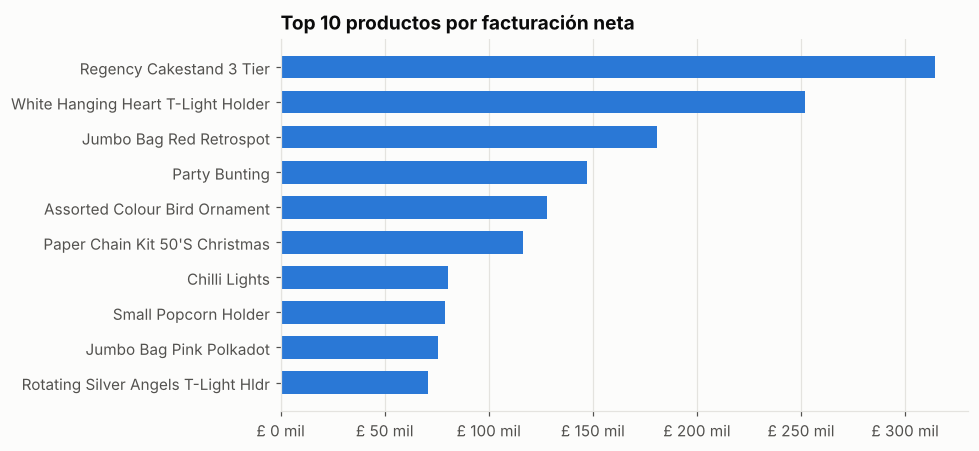

In [27]:
# Top productos por facturación NETA (ventas − devoluciones y anulaciones), sin ventas con precio atípico
neto_prod = (ventas[~ventas.precio_atipico].groupby("codigo")["importe"].sum()
             .add(devoluciones.groupby("codigo")["importe"].sum(), fill_value=0))
nombres = ventas.drop_duplicates("codigo").set_index("codigo")["descripcion"]
top = neto_prod.sort_values(ascending=False).head(10).rename("importe").to_frame()
top["descripcion"] = nombres.reindex(top.index)
top = top.reset_index()
fig, ax = plt.subplots(figsize=(9, 4.2))
orden = top.iloc[::-1]
ax.barh(orden["descripcion"].str.title(), orden["importe"], color=AZUL, height=0.65)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(libras))
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 productos por facturación neta")
plt.tight_layout(); plt.savefig("../figures/06_top_productos.png", dpi=150, bbox_inches="tight")
print(f"Los 10 productos principales suman el {top['importe'].sum() / ventas['importe'].sum():.1%} de la facturación "
      f"(catálogo de {miles(ventas['codigo'].nunique())} productos)")

## 7. Conclusiones

### Sobre los datos: lo que se encontró sin buscarlo

| Hallazgo | Magnitud | Qué habría pasado sin detectarlo |
|---|---|---|
| Las dos hojas repiten el 1–9 de diciembre de 2010 | 22.523 filas | Ventas de ese período contadas dos veces |
| Ajustes de inventario mezclados con ventas | 5.936 filas | Unidades "vendidas" que en realidad son mermas |
| Pedidos anulados dentro de las 24 h | £ 351 mil | Tasa de devolución casi duplicada (3,7% en vez de 1,9%) |
| Refacturación de un lote a otro cliente | 45 líneas, 87.167 unidades | Productos con 49% de "devolución" falsa |
| Clientes faltantes que no son aleatorios (AUC 0,875) | 22% de las líneas, 13% de la facturación | Descartarlos sesga el análisis hacia el canal mayorista |
| Precios a más de 10 veces del habitual (hasta 2.755 veces), 86% en pedidos sin cliente | 881 ventas, £ 76 mil | Precios promedio y márgenes por producto distorsionados |
| El z-score robusto "de manual" no sirve acá | marcaría 26.643 ventas, la mayoría con precio minorista normal | Se habrían borrado ventas reales |

**Lección metodológica:** las técnicas estándar (descartar faltantes, z-score) dan resultados incorrectos si no se adaptan a la estructura del negocio. La limpieza correcta salió de entender **qué representa cada fila**, no de aplicar una receta.

### Sobre el negocio

1. **Negocio estable, muy estacional.** La facturación neta creció apenas +1,8% interanual (£ 9,19 M → £ 9,35 M), y de septiembre a noviembre se concentra el 36–38% del año. El stock, la logística y la atención al cliente tienen que dimensionarse para ese pico, que se repite todos los años.
2. **Dependencia de pocos clientes.** El 1% de los clientes registrados genera el 31% de la facturación y el 20% genera el 77%. Perder un cliente grande pesa más que cualquier campaña: conviene un programa de seguimiento de cuentas clave y alertas cuando un cliente grande deja de comprar.
3. **Retención mejorable.** El 64% de los clientes del primer año volvió a comprar en el segundo. Con un negocio que no crece, recuperar parte del 36% restante es la palanca más directa.
4. **Las devoluciones se concentran en productos frágiles.** Con la métrica por frecuencia, los productos con más devoluciones son de vidrio y cerámica (soportes de torta, teteras, frascos, espejos) y luces. Revisar embalaje y proveedores de esas líneas ataca la causa probable: roturas en el envío y fallas.
5. **Mercado concentrado en el Reino Unido (86%).** Irlanda, Países Bajos, Alemania y Francia son los siguientes mercados, cada uno con menos del 4%.
6. **Catálogo de cola larga.** Los 10 productos principales suman solo el 7% de la facturación, sobre un catálogo de 4.725 productos: el negocio depende de la variedad más que de pocos productos estrella.

### Recomendaciones para la carga de datos

- Separar en el sistema las **ventas** de los **ajustes de inventario** y los **ajustes contables**, que hoy comparten la misma tabla.
- Hacer **obligatorio el cliente** (o un identificador de "cliente invitado") en cada pedido.
- Pedir **confirmación** cuando un precio se desvía más de 10 veces del habitual del producto.
- Registrar el **motivo de cada factura "C"**: devolución, anulación o refacturación.

### Qué habilita este dataset limpio

- **Pronóstico de demanda:** la serie de ventas netas, sin anulaciones ni duplicados, se puede modelar con estacionalidad anual para planificar compras antes del pico de septiembre a noviembre.
- **Segmentación y valor de vida del cliente (RFM / CLV):** con las devoluciones bien atribuidas a cada cliente y la aclaración de que solo cubre clientes registrados.
- **Alertas automáticas:** las mismas reglas del pipeline se pueden correr cada día sobre los datos nuevos para detectar precios mal cargados o archivos duplicados antes de que lleguen a los reportes.